# Atividade Integradora I – Ciência de Dados
**EletroTech Solutions S.A.** – análise da base de 500 registros de produção (dados sintéticos).

Etapas: 1) Preparação, 2) Amostragem e Estatística Descritiva, 3) Teste de hipóteses, 4) Correlação e regressão, 5) Séries temporais, 6) Comunicação.

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from pathlib import Path

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

Path("figuras").mkdir(exist_ok=True)
SEED = 20261029

## 1. Preparação dos dados

In [1]:
df = pd.read_csv("eletrotech_base_500_registros.csv", encoding="utf-8-sig", parse_dates=["data"])
print(df.shape)
df.dtypes

NameError: name 'pd' is not defined

In [3]:
# Valores ausentes, duplicatas e consistência
print("Ausentes por coluna:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nIDs duplicados:", df["id_registro"].duplicated().sum())
print("Linhas duplicadas:", df.duplicated().sum())
print("Defeituosas > produzidas:", (df["unidades_defeituosas"] > df["unidades_produzidas"]).sum())
print("Parada > horas planejadas:", (df["horas_parada_maquina"] > df["horas_planejadas"]).sum())
print("Datas em ordem crescente:", df["data"].is_monotonic_increasing)
df.describe().T.round(2)

Ausentes por coluna:
temperatura_ambiente_c       5
experiencia_operador_anos    4
consumo_energia_kwh          3
dtype: int64

IDs duplicados: 0
Linhas duplicadas: 0
Defeituosas > produzidas: 0
Parada > horas planejadas: 0
Datas em ordem crescente: True


,count,mean,min,25%,50%,75%,max,std
data,500,2025-12-17 16:48:00,2025-01-02 00:00:00,2025-06-25 18:00:00,2025-12-17 12:00:00,2026-06-10 06:00:00,2026-12-02 00:00:00,NaN
horas_planejadas,500.0,7.993,7.5,8.0,8.0,8.0,8.5,0.27313
horas_parada_maquina,500.0,0.77578,0.01,0.31,0.61,1.02,4.16,0.650301
idade_maquina_anos,500.0,6.608,1.0,4.0,7.0,10.0,12.0,3.425464
temperatura_ambiente_c,495.0,24.851111,13.0,21.7,24.8,28.1,36.3,4.556611
experiencia_operador_anos,496.0,8.137097,1.0,4.0,8.0,12.0,15.0,4.415464
unidades_produzidas,500.0,181.898,78.0,138.75,163.0,194.0,377.0,64.684308
unidades_defeituosas,500.0,6.778,1.0,4.0,6.0,9.0,24.0,3.19078
consumo_energia_kwh,497.0,236.162575,108.7,207.4,241.3,271.0,376.9,55.850324
residuo_kg,500.0,4.655,0.5,3.0,4.4,6.0,12.1,2.195303


In [4]:
# Tratamento: os ausentes ficam como NaN e cada análise usa só os registros completos
# nas variáveis que precisa (são só 12 valores em 500 registros e nenhum em campo-chave).
# Variáveis derivadas (horas efetivas com mínimo de 1 h, como no gerador dos dados):
df["horas_efetivas"] = (df["horas_planejadas"] - df["horas_parada_maquina"]).clip(lower=1)
df["prod_hora_efetiva"] = df["unidades_produzidas"] / df["horas_efetivas"]
df["prod_hora_planejada"] = df["unidades_produzidas"] / df["horas_planejadas"]
df["taxa_defeitos"] = df["unidades_defeituosas"] / df["unidades_produzidas"]
df["energia_por_unidade"] = df["consumo_energia_kwh"] / df["unidades_produzidas"]
df[["horas_efetivas", "prod_hora_efetiva", "prod_hora_planejada", "taxa_defeitos", "energia_por_unidade"]].describe().round(3)

,horas_efetivas,prod_hora_efetiva,prod_hora_planejada,taxa_defeitos,energia_por_unidade
count,500.000,500.000,500.000,500.000,497.000
mean,7.217,25.214,22.778,0.039,1.470
std,0.705,8.572,8.120,0.018,0.525
min,4.340,12.871,9.176,0.006,0.361
25%,6.887,18.984,17.238,0.026,1.336
50%,7.350,23.009,20.625,0.036,1.614
75%,7.720,25.937,23.912,0.050,1.826
max,8.380,49.153,47.125,0.109,2.743


### Dicionário de dados (variáveis derivadas)
- `horas_efetivas` = horas planejadas − horas de parada (mínimo 1 h)
- `prod_hora_efetiva` = unidades produzidas ÷ horas efetivas
- `prod_hora_planejada` = unidades produzidas ÷ horas planejadas
- `taxa_defeitos` = unidades defeituosas ÷ unidades produzidas
- `energia_por_unidade` = consumo de energia (kWh) ÷ unidades produzidas

## 2. Amostragem

In [5]:
# População: os 500 registros. Unidade de análise: um registro (um turno de produção em um dia).
# Comparação de três técnicas com n = 125 (25% da população).
n_amostra = 125
rng = np.random.default_rng(SEED)

# a) Aleatória simples
amostra_simples = df.sample(n=n_amostra, random_state=SEED)

# b) Sistemática: intervalo k = 500/125 = 4, início aleatório entre 0 e 3
k = len(df) // n_amostra
inicio = rng.integers(0, k)
amostra_sistematica = df.iloc[inicio::k]

# c) Estratificada proporcional por produto
amostra_estratificada = df.groupby("produto", group_keys=False).sample(frac=0.25, random_state=SEED)

def resumo(d):
    return pd.Series({
        "n": len(d),
        "prod_hora_efetiva_media": d["prod_hora_efetiva"].mean(),
        "taxa_defeitos": d["unidades_defeituosas"].sum() / d["unidades_produzidas"].sum(),
        "parada_media_h": d["horas_parada_maquina"].mean(),
        **{f"%{p}": 100 * (d["produto"] == p).mean() for p in sorted(df["produto"].unique())},
    })

comparacao = pd.DataFrame({
    "População": resumo(df),
    "Aleatória simples": resumo(amostra_simples),
    "Sistemática": resumo(amostra_sistematica),
    "Estratificada": resumo(amostra_estratificada),
}).T.round(3)
comparacao

,n,prod_hora_efetiva_media,taxa_defeitos,parada_media_h,%Ar-condicionado,%Geladeira,%Lavadora,%Micro-ondas
População,500.0,25.214,0.037,0.776,23.2,32.6,25.6,18.6
Aleatória simples,125.0,25.455,0.037,0.740,27.2,31.2,23.2,18.4
Sistemática,125.0,26.287,0.038,0.756,24.8,22.4,31.2,21.6
Estratificada,125.0,25.400,0.036,0.757,23.2,32.8,25.6,18.4


In [6]:
# Técnica adotada: estratificada proporcional por produto.
# Inferência: IC de 95% para a produtividade média por hora efetiva, por produto, a partir da amostra.
linhas = []
for prod, g in amostra_estratificada.groupby("produto"):
    x = g["prod_hora_efetiva"]
    ic = stats.t.interval(0.95, len(x) - 1, loc=x.mean(), scale=stats.sem(x))
    pop = df.loc[df["produto"] == prod, "prod_hora_efetiva"].mean()
    linhas.append([prod, len(x), x.mean(), ic[0], ic[1], pop, ic[0] <= pop <= ic[1]])
ic_amostra = pd.DataFrame(linhas, columns=["produto", "n", "média_amostra", "IC95_inf", "IC95_sup", "média_população", "IC contém a média?"]).round(2)
ic_amostra

,produto,n,média_amostra,IC95_inf,IC95_sup,média_população,IC contém a média?
0,Ar-condicionado,29,25.22,24.33,26.12,24.72,True
1,Geladeira,41,18.19,17.75,18.64,17.96,True
2,Lavadora,32,23.12,22.48,23.76,22.91,True
3,Micro-ondas,23,41.64,40.55,42.73,41.72,True


## 3. Estatística descritiva (base completa, 500 registros)

In [7]:
def descritiva(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({
        "n": s.size, "média": s.mean(), "mediana": s.median(), "moda": s.round(1).mode().iloc[0],
        "mín": s.min(), "máx": s.max(), "amplitude": s.max() - s.min(),
        "variância": s.var(), "desvio-padrão": s.std(), "Q1": q1, "Q3": q3, "IIQ": q3 - q1,
    })

variaveis = ["unidades_produzidas", "horas_parada_maquina", "consumo_energia_kwh", "unidades_defeituosas",
             "prod_hora_efetiva", "energia_por_unidade"]
desc_geral = pd.DataFrame({v: descritiva(df[v]) for v in variaveis}).T.round(3)
desc_geral

,n,média,mediana,moda,mín,máx,amplitude,variância,desvio-padrão,Q1,Q3,IIQ
unidades_produzidas,500.0,181.898,163.000,130.0,78.000,377.000,299.000,4184.060,64.684,138.750,194.000,55.250
horas_parada_maquina,500.0,0.776,0.610,0.7,0.010,4.160,4.150,0.423,0.650,0.310,1.020,0.710
consumo_energia_kwh,497.0,236.163,241.300,218.0,108.700,376.900,268.200,3119.259,55.850,207.400,271.000,63.600
unidades_defeituosas,500.0,6.778,6.000,4.0,1.000,24.000,23.000,10.181,3.191,4.000,9.000,5.000
prod_hora_efetiva,500.0,25.214,23.009,23.3,12.871,49.153,36.281,73.481,8.572,18.984,25.937,6.953
energia_por_unidade,497.0,1.470,1.614,1.7,0.361,2.743,2.383,0.276,0.525,1.336,1.826,0.490


In [8]:
# Indicadores gerais (taxa de defeitos = soma dos defeitos / soma das unidades)
taxa_geral = df["unidades_defeituosas"].sum() / df["unidades_produzidas"].sum()
prod_hora_geral = df["unidades_produzidas"].sum() / df["horas_efetivas"].sum()
energia_unid_geral = df["consumo_energia_kwh"].sum() / df.loc[df["consumo_energia_kwh"].notna(), "unidades_produzidas"].sum()
print(f"Taxa de defeitos geral: {taxa_geral:.4%}")
print(f"Produtividade por hora efetiva (total): {prod_hora_geral:.2f} un/h")
print(f"Energia por unidade (total): {energia_unid_geral:.3f} kWh/un")
print(f"Parada média: {df['horas_parada_maquina'].mean():.3f} h (mediana {df['horas_parada_maquina'].median():.2f} h)")

Taxa de defeitos geral: 3.7263%
Produtividade por hora efetiva (total): 25.20 un/h
Energia por unidade (total): 1.301 kWh/un
Parada média: 0.776 h (mediana 0.61 h)


In [9]:
# Por produto
def por_grupo(col):
    g = df.groupby(col)
    return pd.DataFrame({
        "registros": g.size(),
        "produção_média": g["unidades_produzidas"].mean(),
        "produção_mediana": g["unidades_produzidas"].median(),
        "produção_dp": g["unidades_produzidas"].std(),
        "prod_hora_efetiva_média": g["prod_hora_efetiva"].mean(),
        "prod_hora_efetiva_dp": g["prod_hora_efetiva"].std(),
        "parada_média_h": g["horas_parada_maquina"].mean(),
        "taxa_defeitos_%": 100 * g["unidades_defeituosas"].sum() / g["unidades_produzidas"].sum(),
        "energia_por_unid": g["consumo_energia_kwh"].sum() / df[df["consumo_energia_kwh"].notna()].groupby(col)["unidades_produzidas"].sum(),
    }).round(3)

tab_produto = por_grupo("produto")
tab_turno = por_grupo("turno")
tab_linha = por_grupo("linha_producao")
print("POR PRODUTO"); print(tab_produto)
print("\nPOR TURNO"); print(tab_turno)
print("\nPOR LINHA"); print(tab_linha)

POR PRODUTO
                 registros  produção_média  produção_mediana  produção_dp  prod_hora_efetiva_média  prod_hora_efetiva_dp  parada_média_h  taxa_defeitos_%  energia_por_unid
produto                                                                                                                                                                    
Ar-condicionado        116         178.922             178.0       20.613                   24.717                 2.032           0.751            4.481             1.672
Geladeira              163         130.411             131.0       15.565                   17.957                 1.391           0.767            4.220             1.917
Lavadora               128         162.578             164.0       19.652                   22.909                 1.643           0.858            3.575             1.398
Micro-ondas             93         302.441             310.0       35.881                   41.725                 3.113        

In [10]:
# Variabilidade por turno dentro de cada produto (coeficiente de variação da produção)
cv = df.groupby(["produto", "turno"])["unidades_produzidas"].agg(lambda s: s.std() / s.mean() * 100).unstack().round(1)
print("CV (%) da produção por produto e turno"); print(cv)
cv_prod_hora = df.groupby("turno")["prod_hora_efetiva"].agg(lambda s: s.std() / s.mean() * 100).round(1)
print("\nCV (%) da produtividade por hora efetiva, por turno:"); print(cv_prod_hora)

CV (%) da produção por produto e turno
turno            Manhã  Noite  Tarde
produto                             
Ar-condicionado   11.0   13.0    9.2
Geladeira         12.2   10.0   12.1
Lavadora          13.0   11.9   10.7
Micro-ondas        9.9   14.5   11.4

CV (%) da produtividade por hora efetiva, por turno:
turno
Manhã    34.0
Noite    33.1
Tarde    34.0
Name: prod_hora_efetiva, dtype: float64


In [11]:
# Valores atípicos no consumo de energia (regra de Tukey: 1,5 × IIQ)
def outliers_iqr(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iiq = q3 - q1
    lim = (q1 - 1.5 * iiq, q3 + 1.5 * iiq)
    return lim, s[(s < lim[0]) | (s > lim[1])]

lim_e, out_e = outliers_iqr(df["consumo_energia_kwh"])
print(f"Energia (geral): limites {lim_e[0]:.1f} a {lim_e[1]:.1f} kWh -> {len(out_e)} atípicos")
print(df.loc[out_e.index, ["id_registro", "produto", "unidades_produzidas", "horas_parada_maquina", "consumo_energia_kwh"]])

lim_u, out_u = outliers_iqr(df["energia_por_unidade"])
print(f"Energia por unidade (geral): limites {lim_u[0]:.2f} a {lim_u[1]:.2f} -> {len(out_u)} atípicos")

# Por produto (o consumo depende do produto)
res = []
for p, g in df.groupby("produto"):
    lim, o = outliers_iqr(g["consumo_energia_kwh"])
    res.append([p, round(lim[0], 1), round(lim[1], 1), len(o)])
print(pd.DataFrame(res, columns=["produto", "lim_inf", "lim_sup", "n_atípicos"]))

# Atípicos de parada de máquina
lim_p, out_p = outliers_iqr(df["horas_parada_maquina"])
print(f"\nParada (geral): limite superior {lim_p[1]:.2f} h -> {len(out_p)} atípicos")

# Média x mediana
print("\nAssimetria (skew):")
print(df[["unidades_produzidas", "horas_parada_maquina", "consumo_energia_kwh", "unidades_defeituosas"]].skew().round(2))

Energia (geral): limites 112.0 a 366.4 kWh -> 6 atípicos
    id_registro          produto  unidades_produzidas  horas_parada_maquina  consumo_energia_kwh
100      ET0101  Ar-condicionado                  224                  0.18                376.9
140      ET0141      Micro-ondas                  296                  0.07                108.7
251      ET0252  Ar-condicionado                  232                  0.36                366.9
295      ET0296  Ar-condicionado                  213                  0.50                372.7
396      ET0397      Micro-ondas                  255                  0.23                111.0
450      ET0451      Micro-ondas                  282                  1.36                111.0
Energia por unidade (geral): limites 0.60 a 2.56 -> 86 atípicos
           produto  lim_inf  lim_sup  n_atípicos
0  Ar-condicionado    222.7    368.9           2
1        Geladeira    186.4    311.0           2
2         Lavadora    166.9    288.1           3
3   

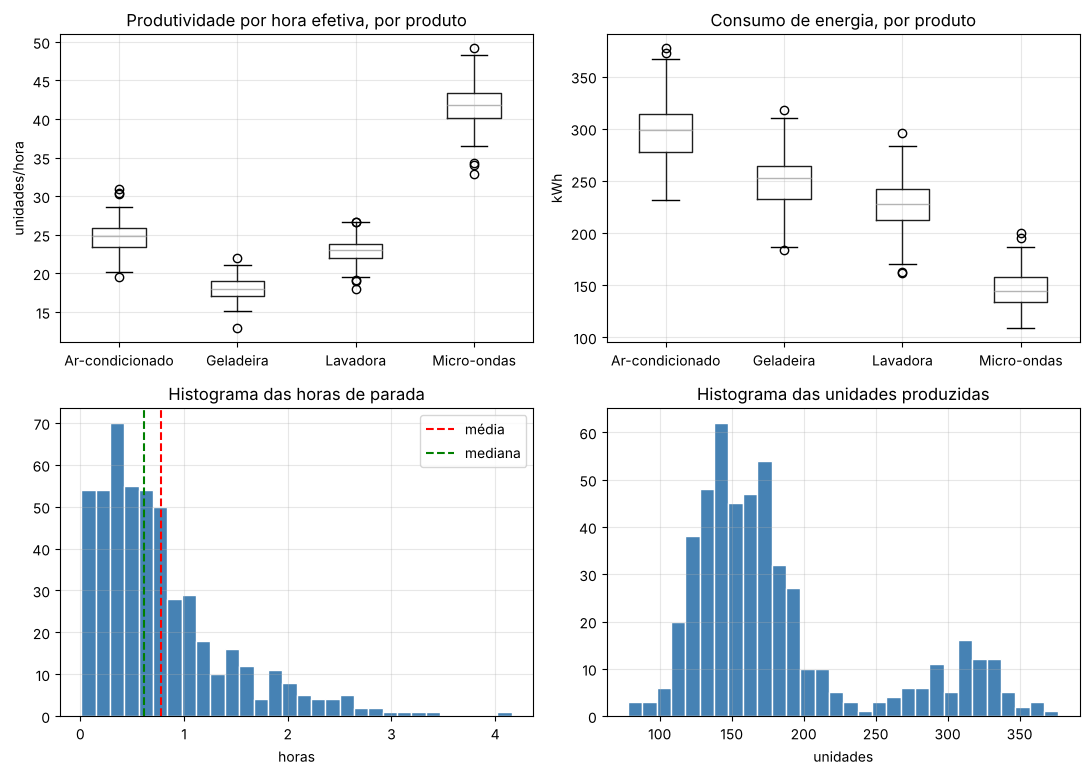

In [12]:
# Gráficos descritivos
fig, ax = plt.subplots(2, 2, figsize=(11, 8))
df.boxplot(column="prod_hora_efetiva", by="produto", ax=ax[0, 0]); ax[0, 0].set_title("Produtividade por hora efetiva, por produto"); ax[0, 0].set_xlabel(""); ax[0, 0].set_ylabel("unidades/hora")
df.boxplot(column="consumo_energia_kwh", by="produto", ax=ax[0, 1]); ax[0, 1].set_title("Consumo de energia, por produto"); ax[0, 1].set_xlabel(""); ax[0, 1].set_ylabel("kWh")
ax[1, 0].hist(df["horas_parada_maquina"], bins=30, color="steelblue", edgecolor="white"); ax[1, 0].axvline(df["horas_parada_maquina"].mean(), color="red", ls="--", label="média"); ax[1, 0].axvline(df["horas_parada_maquina"].median(), color="green", ls="--", label="mediana"); ax[1, 0].legend(); ax[1, 0].set_title("Histograma das horas de parada"); ax[1, 0].set_xlabel("horas")
ax[1, 1].hist(df["unidades_produzidas"], bins=30, color="steelblue", edgecolor="white"); ax[1, 1].set_title("Histograma das unidades produzidas"); ax[1, 1].set_xlabel("unidades")
plt.suptitle(""); plt.tight_layout(); plt.savefig("figuras/fig1_descritiva.png", dpi=130); plt.show()

## 4. Teste de hipóteses: taxa de defeitos entre turnos

In [13]:
# H0: a taxa de defeitos de Manhã e Noite é igual; H1: são diferentes. alfa = 0,05
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

resumo_turno = df.groupby("turno").agg(defeitos=("unidades_defeituosas", "sum"), produzidas=("unidades_produzidas", "sum"))
resumo_turno["taxa_%"] = 100 * resumo_turno["defeitos"] / resumo_turno["produzidas"]
print(resumo_turno.round(3))

a, b = "Manhã", "Noite"
x = np.array([resumo_turno.loc[a, "defeitos"], resumo_turno.loc[b, "defeitos"]])
nobs = np.array([resumo_turno.loc[a, "produzidas"], resumo_turno.loc[b, "produzidas"]])
p_pool = x.sum() / nobs.sum()
print("\nCondições: n*p e n*(1-p) >= 10 em ambos os grupos ->", all(nobs * p_pool >= 10) and all(nobs * (1 - p_pool) >= 10))

z, p_valor = proportions_ztest(x, nobs)
dif = x[0] / nobs[0] - x[1] / nobs[1]
ic = confint_proportions_2indep(x[0], nobs[0], x[1], nobs[1], method="wald")
print(f"z = {z:.3f}, valor-p = {p_valor:.4f}")
print(f"Diferença ({a} - {b}) = {100*dif:.3f} p.p.  IC95%: [{100*ic[0]:.3f}; {100*ic[1]:.3f}] p.p.")

       defeitos  produzidas  taxa_%
turno                              
Manhã      1414       37761   3.745
Noite       872       23287   3.745
Tarde      1103       29901   3.689

Condições: n*p e n*(1-p) >= 10 em ambos os grupos -> True
z = 0.000, valor-p = 0.9999
Diferença (Manhã - Noite) = 0.000 p.p.  IC95%: [-0.310; 0.310] p.p.


In [14]:
# Verificações: (1) qui-quadrado entre os 3 turnos, (2) teste por registro (Welch),
# (3) modelo binomial controlando pelo produto.
tabela = np.array([resumo_turno["defeitos"], resumo_turno["produzidas"] - resumo_turno["defeitos"]]).T
chi2, p_chi, gl, _ = stats.chi2_contingency(tabela)
print(f"Qui-quadrado (3 turnos): chi2 = {chi2:.2f}, gl = {gl}, valor-p = {p_chi:.4f}")

t, p_t = stats.ttest_ind(df.loc[df.turno == a, "taxa_defeitos"], df.loc[df.turno == b, "taxa_defeitos"], equal_var=False)
print(f"Welch nas taxas por registro ({a} x {b}): t = {t:.3f}, valor-p = {p_t:.4f}")

df["nao_defeituosas"] = df["unidades_produzidas"] - df["unidades_defeituosas"]
glm1 = smf.glm("unidades_defeituosas + nao_defeituosas ~ C(turno, Treatment('Manhã'))", data=df, family=sm.families.Binomial()).fit()
glm2 = smf.glm("unidades_defeituosas + nao_defeituosas ~ C(turno, Treatment('Manhã')) + C(produto)", data=df, family=sm.families.Binomial()).fit()
for nome, m in [("só turno", glm1), ("turno + produto", glm2)]:
    t_ = m.summary2().tables[1]
    t_ = t_[t_.index.str.contains("turno")]
    t_["razão_de_chances"] = np.exp(t_["Coef."])
    print(f"\nModelo binomial ({nome}):"); print(t_[["Coef.", "P>|z|", "razão_de_chances"]].round(4))

print(f"\nRazão Pearson chi2/gl do modelo com produto (1 = sem sobredispersão): {glm2.pearson_chi2 / glm2.df_resid:.2f}")
print("\nMistura de produtos por turno (%):")
print((pd.crosstab(df["turno"], df["produto"], normalize="index") * 100).round(1))

Qui-quadrado (3 turnos): chi2 = 0.17, gl = 2, valor-p = 0.9167
Welch nas taxas por registro (Manhã x Noite): t = -0.023, valor-p = 0.9816

Modelo binomial (só turno):
                                        Coef.   P>|z|  razão_de_chances
C(turno, Treatment('Manhã'))[T.Noite] -0.0000  0.9999            1.0000
C(turno, Treatment('Manhã'))[T.Tarde] -0.0156  0.7035            0.9845

Modelo binomial (turno + produto):
                                        Coef.   P>|z|  razão_de_chances
C(turno, Treatment('Manhã'))[T.Noite] -0.0258  0.5571            0.9745
C(turno, Treatment('Manhã'))[T.Tarde] -0.0259  0.5269            0.9744

Razão Pearson chi2/gl do modelo com produto (1 = sem sobredispersão): 1.30

Mistura de produtos por turno (%):
produto  Ar-condicionado  Geladeira  Lavadora  Micro-ondas
turno                                                     
Manhã               22.7       31.8      24.2         21.2
Noite               23.9       35.5      24.6         15.9
Tarde            

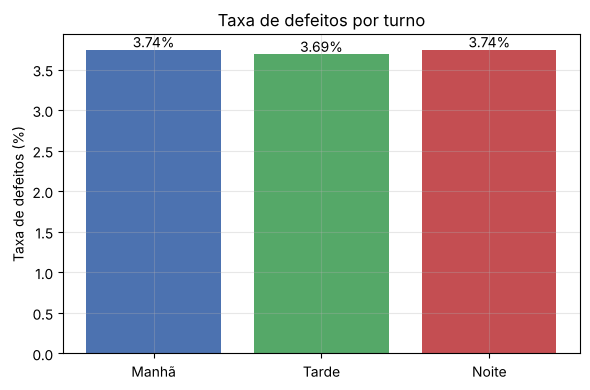

In [15]:
fig, ax = plt.subplots(figsize=(6, 4))
taxas = resumo_turno["taxa_%"].reindex(["Manhã", "Tarde", "Noite"])
ax.bar(taxas.index, taxas.values, color=["#4c72b0", "#55a868", "#c44e52"])
for i, v in enumerate(taxas.values):
    ax.text(i, v + 0.03, f"{v:.2f}%", ha="center")
ax.set_ylabel("Taxa de defeitos (%)"); ax.set_title("Taxa de defeitos por turno")
plt.tight_layout(); plt.savefig("figuras/fig2_turnos.png", dpi=130); plt.show()

## 5. Correlação e regressão

In [16]:
vars_cand = ["horas_parada_maquina", "horas_planejadas", "idade_maquina_anos", "experiencia_operador_anos",
             "temperatura_ambiente_c", "unidades_produzidas"]
alvo = "prod_hora_planejada"

# Correlações (Pearson e Spearman) com a produtividade por hora planejada
corr = pd.DataFrame({
    "pearson": df[vars_cand].corrwith(df[alvo]),
    "spearman": df[vars_cand].corrwith(df[alvo], method="spearman"),
}).round(3)
corr["valor-p (pearson)"] = [stats.pearsonr(*df[[v, alvo]].dropna().T.values)[1] for v in vars_cand]
corr

,pearson,spearman,valor-p (pearson)
horas_parada_maquina,-0.273,-0.314,5.332551e-10
horas_planejadas,-0.074,-0.085,9.724603e-02
idade_maquina_anos,-0.015,-0.045,7.445078e-01
experiencia_operador_anos,0.072,0.082,1.105145e-01
temperatura_ambiente_c,-0.070,-0.054,1.209787e-01
unidades_produzidas,0.995,0.990,0.000000e+00


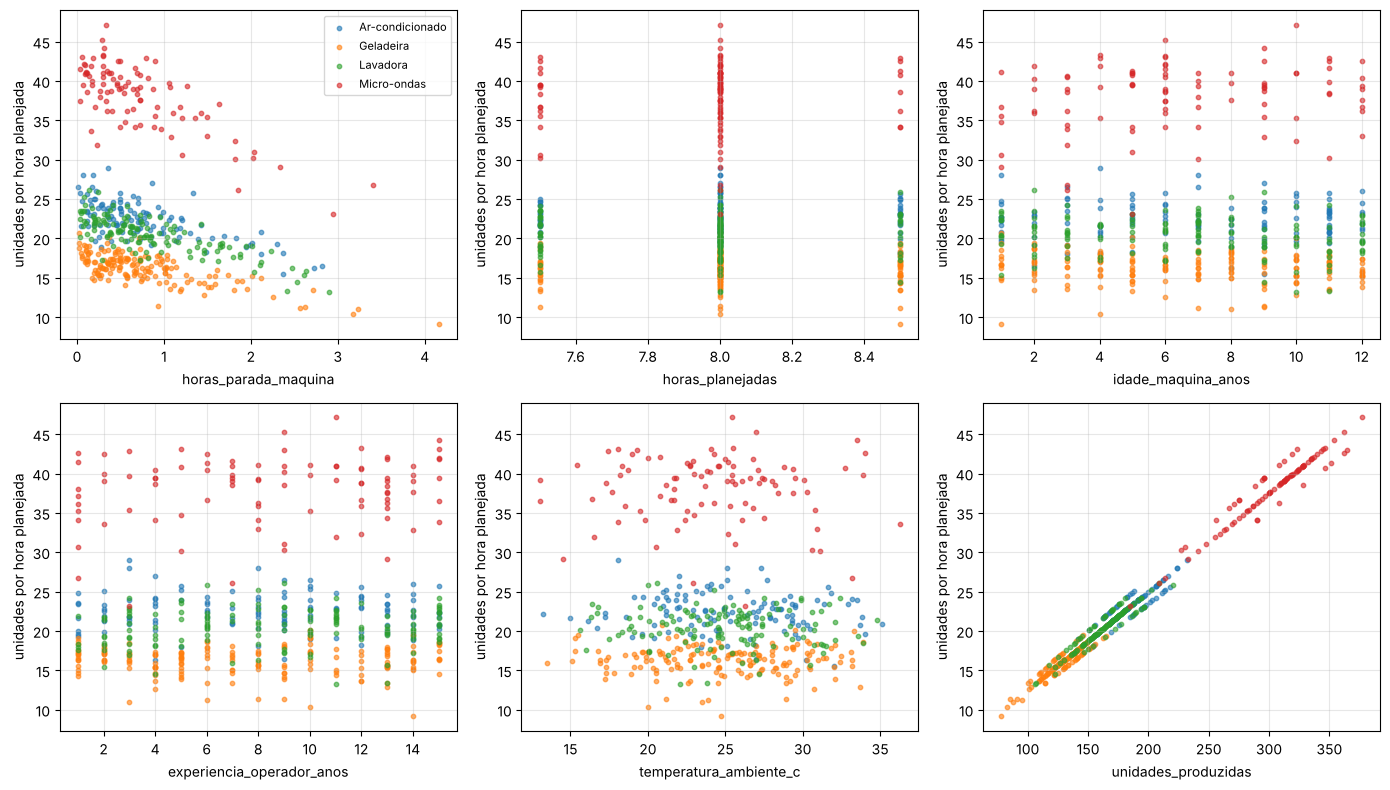

In [17]:
# Gráficos de dispersão
fig, ax = plt.subplots(2, 3, figsize=(14, 8))
for a_, v in zip(ax.ravel(), vars_cand):
    for p, g in df.groupby("produto"):
        a_.scatter(g[v], g[alvo], s=10, alpha=0.6, label=p)
    a_.set_xlabel(v); a_.set_ylabel("unidades por hora planejada")
ax[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figuras/fig3_dispersao.png", dpi=130); plt.show()

In [18]:
# Correlação dentro de cada produto (parada x produtividade)
print(df.groupby("produto").apply(lambda g: pd.Series({"pearson": g["horas_parada_maquina"].corr(g[alvo]),
                                                       "inclinação": np.polyfit(g["horas_parada_maquina"], g[alvo], 1)[0]})).round(3))

                 pearson  inclinação
produto                             
Ar-condicionado   -0.656      -2.601
Geladeira         -0.736      -2.063
Lavadora          -0.787      -2.771
Micro-ondas       -0.754      -5.076


In [19]:
# Modelo 1: regressão simples (produtividade por hora planejada ~ parada)
m1 = smf.ols("prod_hora_planejada ~ horas_parada_maquina", data=df).fit()
print(m1.summary().tables[1]); print(f"R2 = {m1.rsquared:.3f}  R2 ajustado = {m1.rsquared_adj:.3f}")

# Modelo 2: múltiplo, controlando pelo produto (ritmos diferentes)
dfm = df.dropna(subset=["temperatura_ambiente_c", "experiencia_operador_anos"])
m2 = smf.ols("prod_hora_planejada ~ horas_parada_maquina + idade_maquina_anos + experiencia_operador_anos + temperatura_ambiente_c + C(produto)", data=dfm).fit()
print("\n", m2.summary().tables[1]); print(f"R2 = {m2.rsquared:.3f}  R2 ajustado = {m2.rsquared_adj:.3f}  n = {int(m2.nobs)}")

                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               25.4228      0.545     46.677      0.000      24.353      26.493
horas_parada_maquina    -3.4096      0.538     -6.334      0.000      -4.467      -2.352
R2 = 0.075  R2 ajustado = 0.073

                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept                    24.5865      0.571     43.033      0.000      23.464      25.709
C(produto)[T.Geladeira]      -6.0893      0.239    -25.526      0.000      -6.558      -5.621
C(produto)[T.Lavadora]       -1.6146      0.252     -6.419      0.000      -2.109      -1.120
C(produto)[T.Micro-ondas]    15.5081      0.274     56.636      0.000      14.970      16.046
horas_parada_maquina         -2.9410      0.137

RMSE = 1.93 un/h  | MAE = 1.44 un/h
Shapiro-Wilk dos resíduos: valor-p = 0.0000
Breusch-Pagan (homocedasticidade): valor-p = 0.0000
Durbin-Watson: 2.09


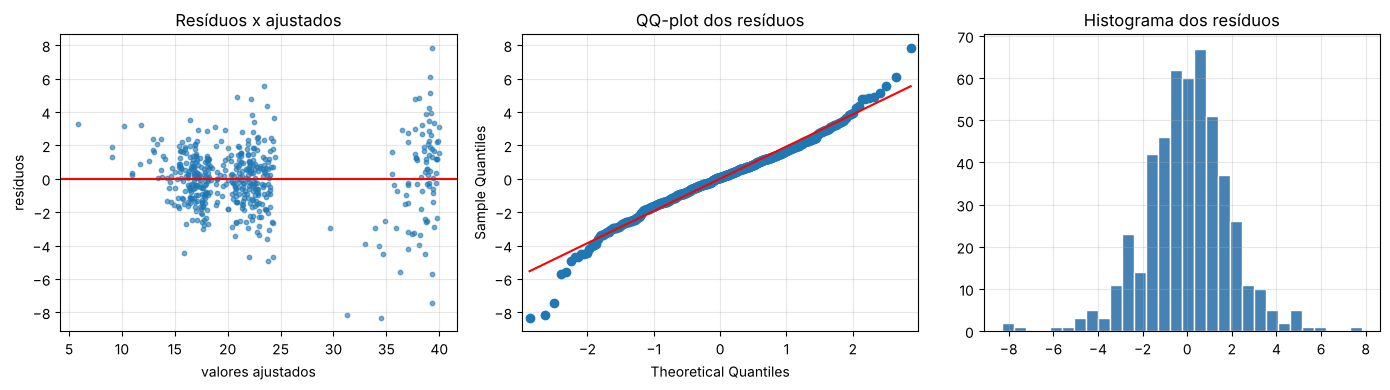

In [20]:
# Qualidade do modelo 2: resíduos e pressupostos
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
res2 = m2.resid
print(f"RMSE = {np.sqrt((res2**2).mean()):.2f} un/h  | MAE = {res2.abs().mean():.2f} un/h")
print(f"Shapiro-Wilk dos resíduos: valor-p = {stats.shapiro(res2)[1]:.4f}")
print(f"Breusch-Pagan (homocedasticidade): valor-p = {het_breuschpagan(res2, m2.model.exog)[1]:.4f}")
print(f"Durbin-Watson: {durbin_watson(res2):.2f}")

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].scatter(m2.fittedvalues, res2, s=10, alpha=0.6); ax[0].axhline(0, color="red"); ax[0].set_xlabel("valores ajustados"); ax[0].set_ylabel("resíduos"); ax[0].set_title("Resíduos x ajustados")
sm.qqplot(res2, line="s", ax=ax[1]); ax[1].set_title("QQ-plot dos resíduos")
ax[2].hist(res2, bins=30, color="steelblue", edgecolor="white"); ax[2].set_title("Histograma dos resíduos")
plt.tight_layout(); plt.savefig("figuras/fig4_residuos.png", dpi=130); plt.show()

In [21]:
# Validação: ajuste em 70% e teste em 30% (separação aleatória)
treino = dfm.sample(frac=0.7, random_state=SEED); teste = dfm.drop(treino.index)
m2t = smf.ols(m2.model.formula, data=treino).fit()
pred = m2t.predict(teste)
print(f"Teste: R2 = {1 - ((teste[alvo]-pred)**2).sum()/((teste[alvo]-teste[alvo].mean())**2).sum():.3f}  RMSE = {np.sqrt(((teste[alvo]-pred)**2).mean()):.2f}")

Teste: R2 = 0.939  RMSE = 1.98


                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept                     3.2163      0.023    140.613      0.000       3.171       3.261
C(produto)[T.Geladeira]      -0.3205      0.010    -33.560      0.000      -0.339      -0.302
C(produto)[T.Lavadora]       -0.0762      0.010     -7.567      0.000      -0.096      -0.056
C(produto)[T.Micro-ondas]     0.5233      0.011     47.738      0.000       0.502       0.545
horas_parada_maquina         -0.1414      0.005    -25.820      0.000      -0.152      -0.131
idade_maquina_anos            0.0019      0.001      1.846      0.066      -0.000       0.004
experiencia_operador_anos    -0.0008      0.001     -1.032      0.303      -0.002       0.001
temperatura_ambiente_c       -0.0006      0.001     -0.767      0.443      -0.002       0.001
R2 = 0.941  R2 ajustado = 0.940
Efeito de 1 h a mais de para

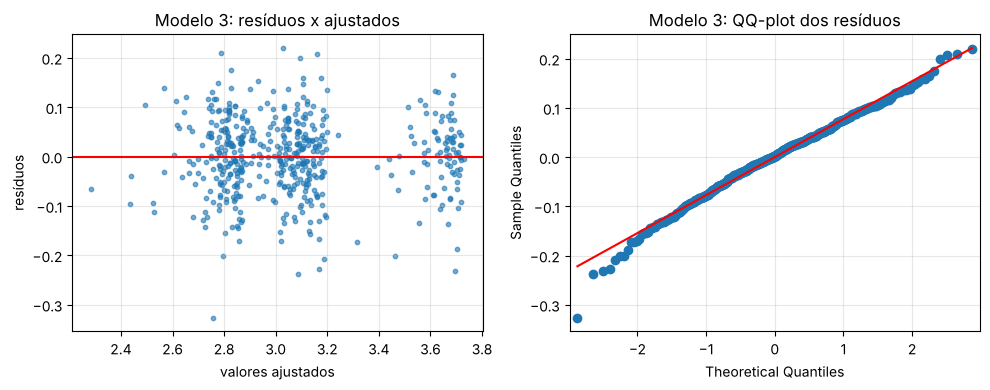

In [22]:
# Modelo 3: log da produtividade (efeito percentual da parada, mesma proporção para todos os produtos)
dfm = dfm.assign(log_prod=np.log(dfm[alvo]))
m3 = smf.ols("log_prod ~ horas_parada_maquina + idade_maquina_anos + experiencia_operador_anos + temperatura_ambiente_c + C(produto)", data=dfm).fit()
print(m3.summary().tables[1]); print(f"R2 = {m3.rsquared:.3f}  R2 ajustado = {m3.rsquared_adj:.3f}")
print(f"Efeito de 1 h a mais de parada: {100 * (np.exp(m3.params['horas_parada_maquina']) - 1):.1f}% na produtividade")
print(f"Shapiro-Wilk: valor-p = {stats.shapiro(m3.resid)[1]:.4f}  | Breusch-Pagan: valor-p = {het_breuschpagan(m3.resid, m3.model.exog)[1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(m3.fittedvalues, m3.resid, s=10, alpha=0.6); ax[0].axhline(0, color="red"); ax[0].set_xlabel("valores ajustados"); ax[0].set_ylabel("resíduos"); ax[0].set_title("Modelo 3: resíduos x ajustados")
sm.qqplot(m3.resid, line="s", ax=ax[1]); ax[1].set_title("Modelo 3: QQ-plot dos resíduos")
plt.tight_layout(); plt.savefig("figuras/fig4b_residuos_log.png", dpi=130); plt.show()

In [23]:
# O que está associado a mais parada? (apoio às recomendações; associação, não causa)
df["faixa_idade"] = np.where(df["idade_maquina_anos"] >= 9, "9 anos ou mais", "até 8 anos")
print(df.groupby("tipo_manutencao")["horas_parada_maquina"].agg(["count", "mean", "median"]).round(2))
print(df.groupby("faixa_idade")["horas_parada_maquina"].agg(["count", "mean", "median"]).round(2))
df["quartil_parada"] = pd.qcut(df["horas_parada_maquina"], 4, labels=["Q1 (menor)", "Q2", "Q3", "Q4 (maior)"])
g = df.groupby("quartil_parada", observed=True)
print((100 * g["unidades_defeituosas"].sum() / g["unidades_produzidas"].sum()).round(2).rename("taxa de defeitos % por quartil de parada"))
print("Correlação parada x entregas no prazo:", round(df["horas_parada_maquina"].corr(df["entregas_no_prazo_pct"]), 3))

                 count  mean  median
tipo_manutencao                     
Corretiva           36  1.78    1.65
Nenhuma            370  0.70    0.56
Preventiva          94  0.70    0.56
                count  mean  median
faixa_idade                        
9 anos ou mais    171  0.97    0.82
até 8 anos        329  0.68    0.47
quartil_parada
Q1 (menor)    3.36
Q2            3.57
Q3            3.85
Q4 (maior)    4.26
Name: taxa de defeitos % por quartil de parada, dtype: float64
Correlação parada x entregas no prazo: -0.702


## 6. Séries temporais e previsão

In [24]:
# Agregação semanal (semanas de segunda a domingo; só semanas completas, com 5 registros)
df["semana"] = df["data"].dt.to_period("W-SUN").dt.start_time
sem = df.groupby("semana").agg(registros=("id_registro", "count"), producao=("unidades_produzidas", "sum"),
                               defeitos=("unidades_defeituosas", "sum"), horas_efetivas=("horas_efetivas", "sum"),
                               parada=("horas_parada_maquina", "sum"))
print("Semanas incompletas removidas:", (sem["registros"] < 5).sum())
sem = sem[sem["registros"] == 5].copy()
sem["taxa_defeitos_%"] = 100 * sem["defeitos"] / sem["producao"]
sem["prod_hora_efetiva"] = sem["producao"] / sem["horas_efetivas"]
sem["t"] = np.arange(len(sem))
sem["mm4_producao"] = sem["producao"].rolling(4).mean()
sem["mm4_defeitos"] = sem["defeitos"].rolling(4).mean()
print(len(sem), "semanas completas")
sem[["producao", "defeitos", "taxa_defeitos_%", "prod_hora_efetiva"]].describe().round(2)

Semanas incompletas removidas: 2
99 semanas completas


,producao,defeitos,taxa_defeitos_%,prod_hora_efetiva
count,99.00,99.00,99.00,99.00
mean,910.59,33.78,3.75,25.20
std,152.42,7.63,0.78,3.99
min,674.00,17.00,1.73,18.83
25%,794.00,28.00,3.14,21.81
50%,888.00,33.00,3.65,25.03
75%,994.50,39.00,4.33,27.61
max,1340.00,58.00,5.83,35.91


In [25]:
# Tendência: regressão temporal simples sobre toda a série e autocorrelação
for col in ["producao", "defeitos", "taxa_defeitos_%"]:
    r = stats.linregress(sem["t"], sem[col])
    print(f"{col}: inclinação = {r.slope:.3f} por semana, R2 = {r.rvalue**2:.4f}, valor-p = {r.pvalue:.4f}")
print("\nAutocorrelação (lag 1) da produção semanal:", round(sem["producao"].autocorr(1), 3))

producao: inclinação = 0.553 por semana, R2 = 0.0109, valor-p = 0.3046
defeitos: inclinação = 0.039 por semana, R2 = 0.0218, valor-p = 0.1445
taxa_defeitos_%: inclinação = 0.002 por semana, R2 = 0.0062, valor-p = 0.4390

Autocorrelação (lag 1) da produção semanal: 0.078


In [26]:
# Separação cronológica: 80% treino / 20% teste
corte = int(len(sem) * 0.8)
treino_s, teste_s = sem.iloc[:corte], sem.iloc[corte:]
print(f"Treino: {len(treino_s)} semanas ({treino_s.index.min().date()} a {treino_s.index.max().date()})")
print(f"Teste:  {len(teste_s)} semanas ({teste_s.index.min().date()} a {teste_s.index.max().date()})")

def avaliar(col):
    X = sm.add_constant(treino_s["t"]); mod = sm.OLS(treino_s[col], X).fit()
    prev = mod.predict(sm.add_constant(teste_s["t"]))
    base = pd.Series(treino_s[col].mean(), index=teste_s.index)       # referência: média do treino
    ingenua = pd.Series(treino_s[col].iloc[-1], index=teste_s.index)  # referência: último valor
    f = lambda p: pd.Series({"MAE": (teste_s[col] - p).abs().mean(), "RMSE": np.sqrt(((teste_s[col] - p) ** 2).mean()),
                             "MAPE_%": 100 * ((teste_s[col] - p).abs() / teste_s[col]).mean()})
    tab = pd.DataFrame({"regressão temporal": f(prev), "média do treino": f(base), "último valor": f(ingenua)}).T.round(2)
    return mod, prev, tab

mod_p, prev_p, tab_p = avaliar("producao")
mod_d, prev_d, tab_d = avaliar("defeitos")
print("PRODUÇÃO semanal (teste)"); print(tab_p)
print(f"\ninclinação (treino): {mod_p.params['t']:.3f} un/semana, valor-p = {mod_p.pvalues['t']:.3f}")
print("\nDEFEITOS semanais (teste)"); print(tab_d)
print(f"\ninclinação (treino): {mod_d.params['t']:.3f} defeitos/semana, valor-p = {mod_d.pvalues['t']:.3f}")

Treino: 79 semanas (2025-01-06 a 2026-07-06)
Teste:  20 semanas (2026-07-13 a 2026-11-23)
PRODUÇÃO semanal (teste)
                       MAE    RMSE  MAPE_%
regressão temporal  132.97  173.75   13.17
média do treino     132.93  173.46   13.18
último valor        192.65  221.47   22.32

inclinação (treino): -0.018 un/semana, valor-p = 0.981

DEFEITOS semanais (teste)
                      MAE   RMSE  MAPE_%
regressão temporal   5.30   6.74   14.02
média do treino      5.46   7.00   14.21
último valor        12.30  13.61   38.01

inclinação (treino): 0.012 defeitos/semana, valor-p = 0.751


In [27]:
# Previsão para as próximas 8 semanas (modelo ajustado em toda a série) – com intervalo de previsão de 95%
X_all = sm.add_constant(sem["t"]); mod_all = sm.OLS(sem["producao"], X_all).fit()
fut = pd.DataFrame({"const": 1.0, "t": np.arange(len(sem), len(sem) + 8)})
pf = mod_all.get_prediction(fut).summary_frame(alpha=0.05)
pf.index = pd.date_range(sem.index.max() + pd.Timedelta(weeks=1), periods=8, freq="W-MON")
print(pf[["mean", "obs_ci_lower", "obs_ci_upper"]].round(0))

             mean  obs_ci_lower  obs_ci_upper
2026-11-30  938.0         630.0        1247.0
2026-12-07  939.0         630.0        1248.0
2026-12-14  939.0         630.0        1248.0
2026-12-21  940.0         631.0        1249.0
2026-12-28  940.0         631.0        1250.0
2027-01-04  941.0         631.0        1251.0
2027-01-11  942.0         632.0        1251.0
2027-01-18  942.0         632.0        1252.0


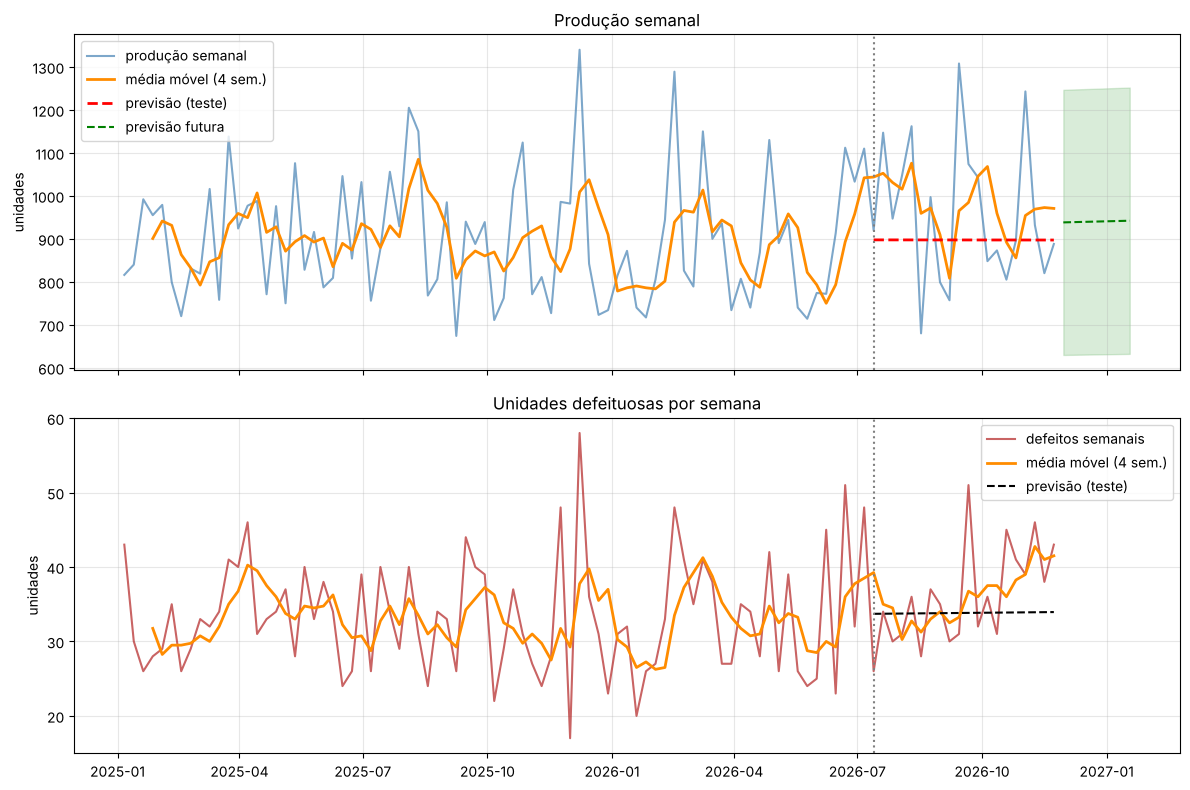

In [28]:
fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax[0].plot(sem.index, sem["producao"], label="produção semanal", color="steelblue", alpha=0.7)
ax[0].plot(sem.index, sem["mm4_producao"], label="média móvel (4 sem.)", color="darkorange", lw=2)
ax[0].plot(teste_s.index, prev_p, label="previsão (teste)", color="red", ls="--", lw=2)
ax[0].plot(pf.index, pf["mean"], color="green", ls="--", label="previsão futura")
ax[0].fill_between(pf.index, pf["obs_ci_lower"], pf["obs_ci_upper"], color="green", alpha=0.15)
ax[0].axvline(teste_s.index.min(), color="gray", ls=":"); ax[0].set_ylabel("unidades"); ax[0].legend(); ax[0].set_title("Produção semanal")
ax[1].plot(sem.index, sem["defeitos"], label="defeitos semanais", color="firebrick", alpha=0.7)
ax[1].plot(sem.index, sem["mm4_defeitos"], label="média móvel (4 sem.)", color="darkorange", lw=2)
ax[1].plot(teste_s.index, prev_d, label="previsão (teste)", color="black", ls="--")
ax[1].axvline(teste_s.index.min(), color="gray", ls=":"); ax[1].set_ylabel("unidades"); ax[1].legend(); ax[1].set_title("Unidades defeituosas por semana")
plt.tight_layout(); plt.savefig("figuras/fig5_series.png", dpi=130); plt.show()

## 7. Comunicação dos resultados: painel de indicadores

In [29]:
painel = pd.DataFrame({
    "Indicador": ["Registros analisados", "Unidades produzidas (total)", "Taxa de defeitos geral", "Produtividade (un/h efetiva)",
                  "Parada média por registro (h)", "Energia por unidade (kWh/un)", "Entregas no prazo (média, %)"],
    "Valor": [len(df), f"{df['unidades_produzidas'].sum():,}".replace(",", "."), f"{100*taxa_geral:.2f}%", f"{prod_hora_geral:.1f}",
              f"{df['horas_parada_maquina'].mean():.2f}", f"{energia_unid_geral:.2f}", f"{df['entregas_no_prazo_pct'].mean():.1f}"],
})
painel

,Indicador,Valor
0,Registros analisados,500
1,Unidades produzidas (total),90.949
2,Taxa de defeitos geral,3.73%
3,Produtividade (un/h efetiva),25.2
4,Parada média por registro (h),0.78
5,Energia por unidade (kWh/un),1.30
6,"Entregas no prazo (média, %)",94.1


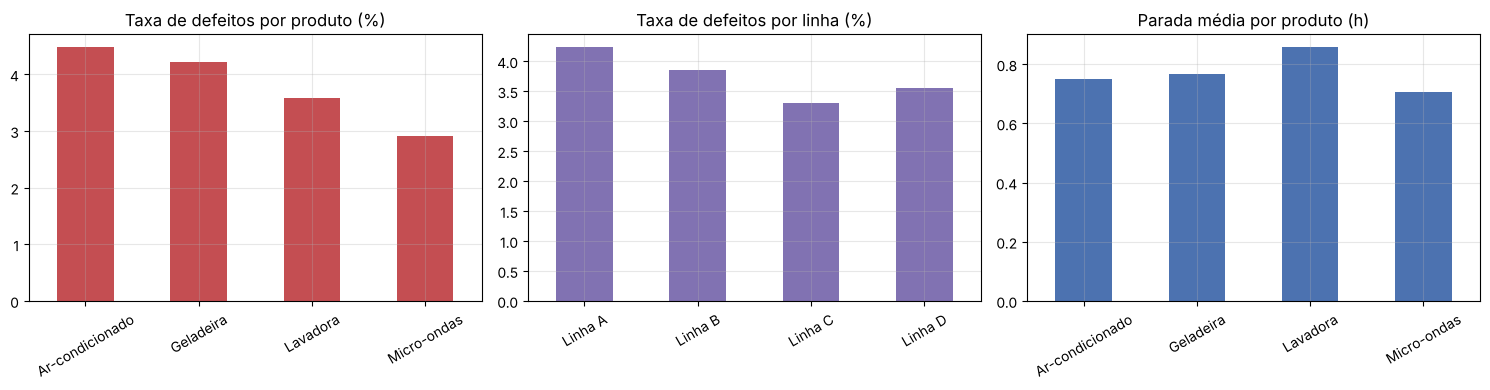

In [30]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
tab_produto["taxa_defeitos_%"].plot.bar(ax=ax[0], color="#c44e52"); ax[0].set_title("Taxa de defeitos por produto (%)"); ax[0].set_xlabel("")
tab_linha["taxa_defeitos_%"].plot.bar(ax=ax[1], color="#8172b2"); ax[1].set_title("Taxa de defeitos por linha (%)"); ax[1].set_xlabel("")
tab_produto["parada_média_h"].plot.bar(ax=ax[2], color="#4c72b0"); ax[2].set_title("Parada média por produto (h)"); ax[2].set_xlabel("")
for a_ in ax: a_.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig("figuras/fig6_gestao.png", dpi=130); plt.show()